# 신약 후보물질 독성 예측 – 데이터 탐색(EDA)
`train.csv`(화합물 8,349개)를 코드로 직접 살펴봅니다. 각 코드 아래에 **쉬운 설명**을 붙였습니다.

> 정답(`label`): **1 = 독성 없음, 0 = 독성 있음** (헷갈리기 쉬우니 주의!)

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100
C0, C1 = '#e4572e', '#2a9d8f'   # 빨강=독성 있음(0), 초록=독성 없음(1)

df = pd.read_csv('train.csv')
fp  = [c for c in df if c[:5] in ('ecfp_','fcfp_','ptfp_')]   # 지문 열 3,072개
num = ['MolWt','clogp','sa_score','qed']                      # 물성 숫자 4개
nm  = {'MolWt':'분자량','clogp':'지용성(clogp)','sa_score':'합성 난이도','qed':'약물 유사성(qed)'}
print('행(화합물) 수:', df.shape[0], '/ 열 수:', df.shape[1])
df[['SMILES']+num+['label']].head()

행(화합물) 수: 8349 / 열 수: 3078


(데이터 비공개: 분자 SMILES가 포함된 표 출력은 제거함)


## 1. 데이터 품질 점검
빈칸, 중복, 이상한 값이 있는지 먼저 봅니다.

In [2]:
print('빈칸(결측치) 개수      :', df.isna().sum().sum())
print('완전히 같은 행 개수     :', df.duplicated().sum())
print('SMILES 중복 개수        :', df.SMILES.duplicated().sum())
print('지문 열이 0/1만 있나?   :', df[fp].isin([0,1]).all().all())
const = [c for c in fp if df[c].nunique()==1]
print('값이 전부 같은 지문 열  :', len(const), '개 →', 'PTFP' if all(c.startswith('ptfp') for c in const) else '', '열들')
rare = (df[fp].mean() < 0.01).sum()
print('1이 1% 미만인 지문 열   :', rare, '개 (거의 정보 없음)')

빈칸(결측치) 개수      : 0
완전히 같은 행 개수     : 0
SMILES 중복 개수        : 0
지문 열이 0/1만 있나?   : True


값이 전부 같은 지문 열  : 49 개 → PTFP 열들
1이 1% 미만인 지문 열   : 554 개 (거의 정보 없음)


→ 빈칸·중복은 없어서 깨끗한 데이터입니다. 다만 **항상 같은 값인 열**은 구분에 도움이 안 되니 모델링 때 빼는 게 좋습니다.

## 2. 정답(label) 비율

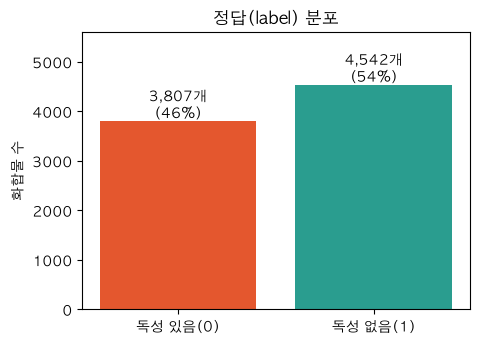

In [3]:
v = df.label.value_counts().sort_index()
plt.figure(figsize=(5,3.6))
bars = plt.bar(['독성 있음(0)','독성 없음(1)'], v.values, color=[C0,C1])
for r,x in zip(bars,v.values): plt.text(r.get_x()+r.get_width()/2, x+60, f'{x:,}개\n({x/len(df):.0%})', ha='center')
plt.ylim(0,5600); plt.ylabel('화합물 수'); plt.title('정답(label) 분포'); plt.show()

→ 두 그룹 크기가 비슷해서, 한쪽만 찍어도 점수가 높게 나오는 문제는 없습니다.

## 3. 물성 숫자 4개 살펴보기

In [4]:
df[num].describe().round(2).rename(columns=nm)

,분자량,지용성(clogp),합성 난이도,약물 유사성(qed)
count,8349.00,8349.00,8349.00,8349.00
mean,443.25,3.79,3.19,0.56
std,88.88,1.38,0.73,0.19
min,94.12,-4.05,1.28,0.02
25%,383.88,2.87,2.66,0.43
50%,441.52,3.74,3.09,0.56
75%,495.64,4.65,3.59,0.70
max,1242.49,9.43,7.31,0.95


In [5]:
# 독성 있음/없음 그룹별 평균 비교
df.groupby('label')[num].mean().round(3).rename(columns=nm).rename(index={0:'독성 있음(0)',1:'독성 없음(1)'})

,분자량,지용성(clogp),합성 난이도,약물 유사성(qed)
label,,,,
독성 있음(0),443.803,4.206,3.126,0.542
독성 없음(1),442.784,3.450,3.240,0.573


→ 그룹 평균이 가장 크게 다른 것은 **지용성(clogp)** 입니다 (독성 있음 4.21 vs 없음 3.45).

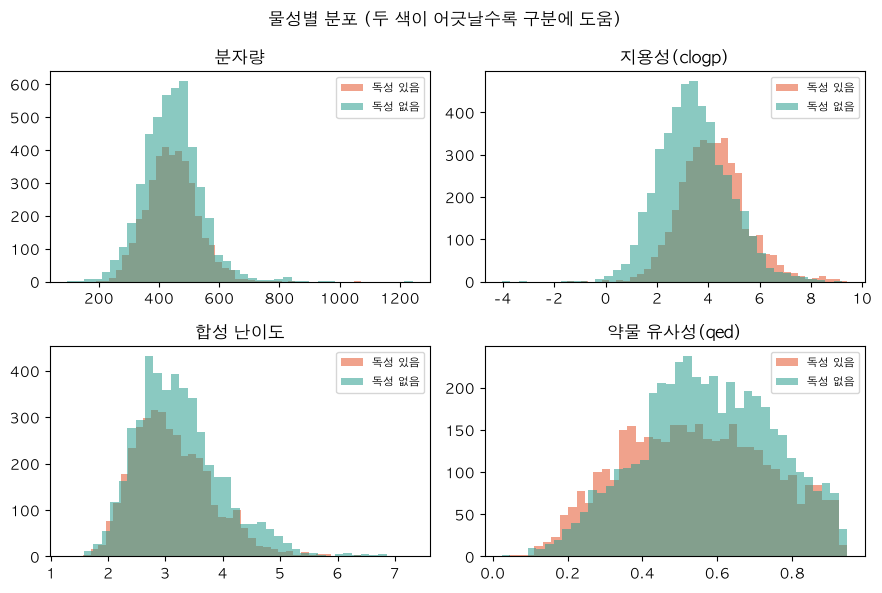

In [6]:
fig, ax = plt.subplots(2,2, figsize=(9,6))
for a,c in zip(ax.flat, num):
    for l,col,n in [(0,C0,'독성 있음'),(1,C1,'독성 없음')]:
        a.hist(df[df.label==l][c], bins=40, alpha=.55, color=col, label=n)
    a.set_title(nm[c]); a.legend(fontsize=8)
plt.suptitle('물성별 분포 (두 색이 어긋날수록 구분에 도움)'); plt.tight_layout(); plt.show()

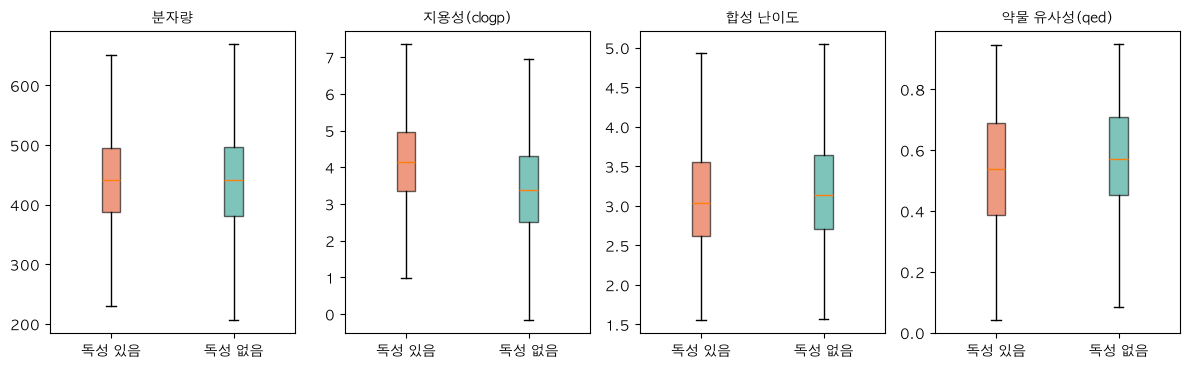

In [7]:
# [추가] 상자그림: 가운데 선=중앙값, 상자=중간 50%의 범위
fig, ax = plt.subplots(1,4, figsize=(12,3.8))
for a,c in zip(ax,num):
    bp = a.boxplot([df[df.label==0][c], df[df.label==1][c]], tick_labels=['독성 있음','독성 없음'], patch_artist=True, showfliers=False)
    for p,col in zip(bp['boxes'],[C0,C1]): p.set_facecolor(col); p.set_alpha(.6)
    a.set_title(nm[c], fontsize=10)
plt.tight_layout(); plt.show()

→ 상자 위치가 확실히 갈리는 건 `clogp` 뿐이고, 분자량은 거의 겹칩니다.

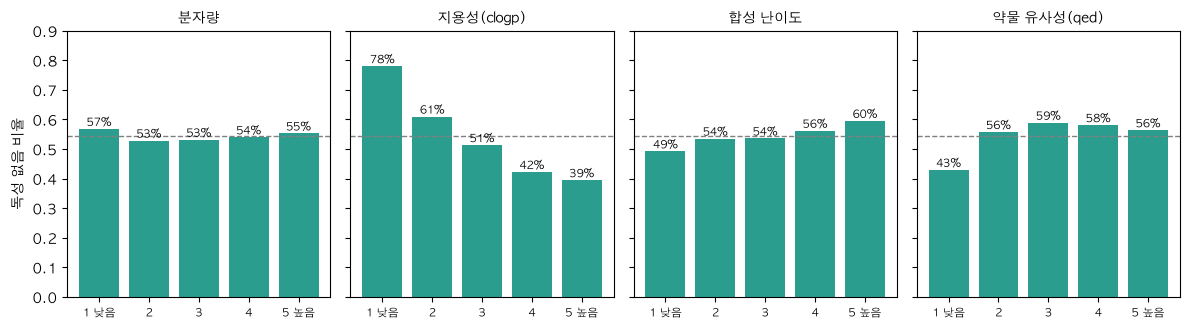

In [8]:
# 각 물성을 낮음→높음 5구간으로 나눠 '독성 없음' 비율 보기 (점선=전체 평균)
fig, ax = plt.subplots(1,4, figsize=(12,3.4), sharey=True)
for a,c in zip(ax,num):
    g = df.groupby(pd.qcut(df[c],5,labels=['1 낮음','2','3','4','5 높음']), observed=True).label.mean()
    a.bar(range(5), g.values, color=C1); a.axhline(df.label.mean(), color='gray', ls='--', lw=1)
    a.set_xticks(range(5)); a.set_xticklabels(g.index, fontsize=8); a.set_title(nm[c], fontsize=10); a.set_ylim(0,.9)
    for i,x in enumerate(g.values): a.text(i, x+.01, f'{x:.0%}', ha='center', fontsize=8)
ax[0].set_ylabel('독성 없음 비율'); plt.tight_layout(); plt.show()

→ `clogp`가 낮은 구간은 78%가 독성 없음, 높은 구간은 39%. **기름에 잘 녹을수록 독성 위험↑**. `qed`는 가장 낮은 구간만 비율이 낮습니다.

## 4. 물성끼리의 관계

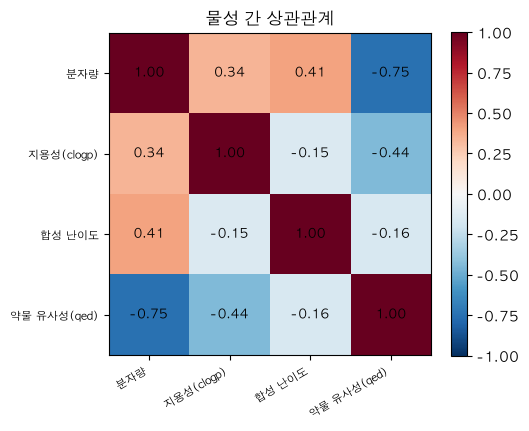

In [9]:
cm = df[num].corr()
plt.figure(figsize=(5.2,4.2)); plt.imshow(cm, cmap='RdBu_r', vmin=-1, vmax=1); plt.colorbar()
l = [nm[c] for c in num]; plt.xticks(range(4), l, rotation=30, ha='right', fontsize=8); plt.yticks(range(4), l, fontsize=8)
for i in range(4):
    for j in range(4): plt.text(j,i,f'{cm.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9)
plt.title('물성 간 상관관계'); plt.show()

→ 분자량과 약물 유사성이 **-0.75**로 강하게 엮여 있어 비슷한 정보를 중복해서 담고 있습니다.

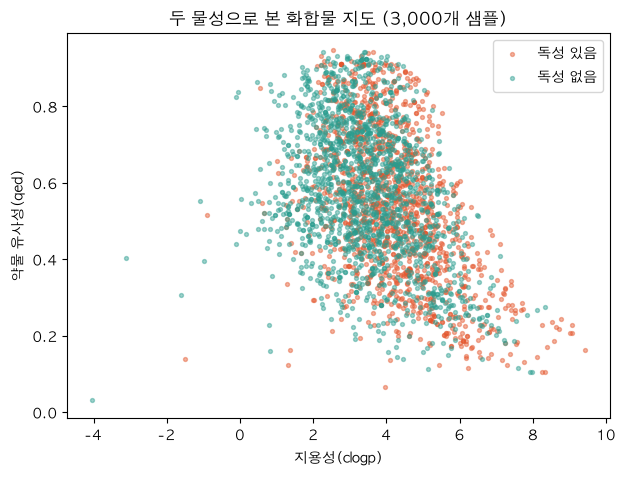

In [10]:
# [추가] 지용성 × 약물 유사성 지도: 점 하나 = 화합물 하나
s = df.sample(3000, random_state=0)
plt.figure(figsize=(7,5))
plt.scatter(s[s.label==0].clogp, s[s.label==0].qed, s=8, c=C0, alpha=.45, label='독성 있음')
plt.scatter(s[s.label==1].clogp, s[s.label==1].qed, s=8, c=C1, alpha=.45, label='독성 없음')
plt.xlabel('지용성(clogp)'); plt.ylabel('약물 유사성(qed)'); plt.legend(); plt.title('두 물성으로 본 화합물 지도 (3,000개 샘플)'); plt.show()

→ 오른쪽(지용성↑)으로 갈수록 빨강이 늘어납니다. 하지만 두 색이 **많이 섞여 있어** 이 두 숫자만으로 선을 긋기는 어렵습니다.

## 5. 분자 이름표(SMILES) 길이와 이상치

        count  mean   std   min   25%   50%   75%    max
label                                                   
독성 있음  3807.0  55.5  12.9  19.0  47.0  55.0  63.0  181.0
독성 없음  4542.0  57.5  16.4   9.0  48.0  56.0  65.0  249.0

분자량 800 초과(매우 큰 분자): 25 개
독성 없음 비율 → 800 초과 그룹: 92%, 나머지: 54%


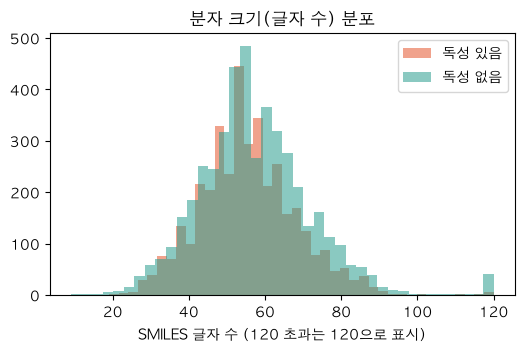

In [11]:
df['smiles_len'] = df.SMILES.str.len()
print(df.groupby('label').smiles_len.describe().round(1).rename(index={0:'독성 있음',1:'독성 없음'}))
print('\n분자량 800 초과(매우 큰 분자):', (df.MolWt>800).sum(), '개')
print('독성 없음 비율 → 800 초과 그룹: %.0f%%, 나머지: %.0f%%' % (100*df[df.MolWt>800].label.mean(), 100*df[df.MolWt<=800].label.mean()))
plt.figure(figsize=(6,3.4))
for l,col,n in [(0,C0,'독성 있음'),(1,C1,'독성 없음')]:
    plt.hist(df[df.label==l].smiles_len.clip(upper=120), bins=40, alpha=.55, color=col, label=n)
plt.xlabel('SMILES 글자 수 (120 초과는 120으로 표시)'); plt.legend(); plt.title('분자 크기(글자 수) 분포'); plt.show()

→ 글자 수(분자 크기)는 두 그룹이 비슷합니다. 다만 **분자량 800 초과의 아주 큰 분자 25개는 92%가 독성 없음**으로 평소(54%)와 다릅니다. 개수가 적어 참고만 하세요.

## 6. 분자 지문(0/1 체크리스트) 살펴보기

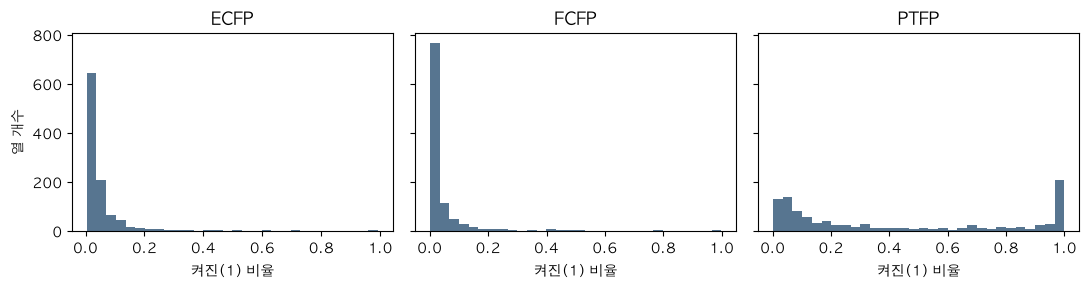

ecfp_ → 화합물 1개당 켜진 비트 평균: 56개 / 1024개
fcfp_ → 화합물 1개당 켜진 비트 평균: 45개 / 1024개
ptfp_ → 화합물 1개당 켜진 비트 평균: 434개 / 1024개


In [12]:
fig, ax = plt.subplots(1,3, figsize=(11,3), sharey=True)
for a,p,n in zip(ax, ['ecfp_','fcfp_','ptfp_'], ['ECFP','FCFP','PTFP']):
    r = df[[c for c in fp if c.startswith(p)]].mean()
    a.hist(r, bins=30, color='#577590'); a.set_title(n); a.set_xlabel('켜진(1) 비율')
ax[0].set_ylabel('열 개수'); plt.tight_layout(); plt.show()
for p in ['ecfp_','fcfp_','ptfp_']:
    print(p, '→ 화합물 1개당 켜진 비트 평균: %.0f개 / 1024개' % df[[c for c in fp if c.startswith(p)]].sum(axis=1).mean())

→ ECFP·FCFP는 대부분 0인 **희소한** 데이터, PTFP는 훨씬 빽빽합니다.

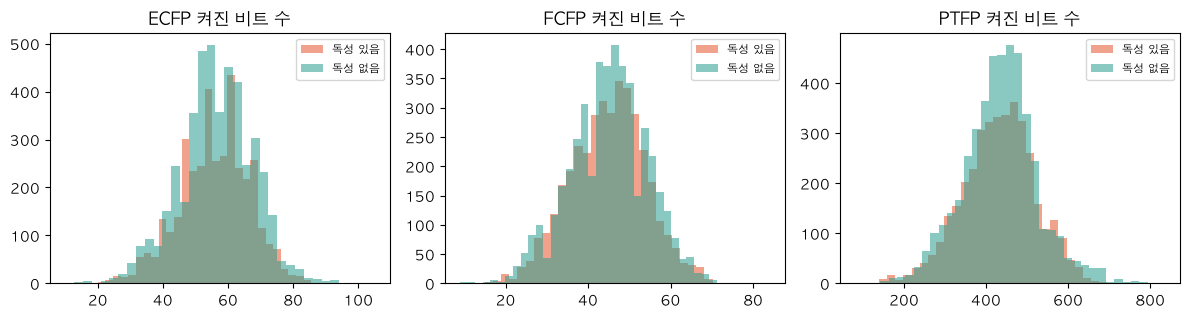

In [13]:
# [추가] 화합물당 켜진 비트 수가 독성과 관련 있나?
fig, ax = plt.subplots(1,3, figsize=(12,3.3))
for a,p,n in zip(ax, ['ecfp_','fcfp_','ptfp_'], ['ECFP','FCFP','PTFP']):
    cnt = df[[c for c in fp if c.startswith(p)]].sum(axis=1)
    for l,col,nn in [(0,C0,'독성 있음'),(1,C1,'독성 없음')]:
        a.hist(cnt[df.label==l], bins=35, alpha=.55, color=col, label=nn)
    a.set_title(n+' 켜진 비트 수'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

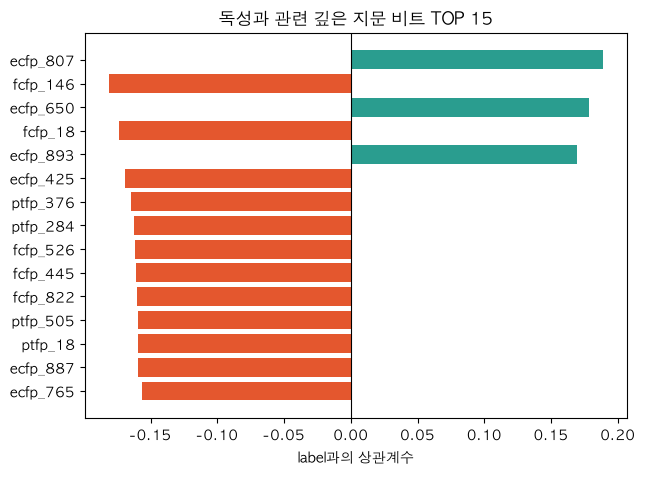

가장 큰 상관계수: 0.19 (낱개 비트 하나로는 약함)


In [14]:
# [추가] 독성과 가장 관련 깊은 지문 비트 TOP 15 (+면 독성 없음 쪽, -면 독성 있음 쪽)
cor = df[fp].corrwith(df.label).dropna()
top = cor.reindex(cor.abs().sort_values(ascending=False).index).head(15)[::-1]
plt.figure(figsize=(7,5)); plt.barh(top.index, top.values, color=[C1 if v>0 else C0 for v in top.values])
plt.axvline(0,color='k',lw=.8); plt.xlabel('label과의 상관계수'); plt.title('독성과 관련 깊은 지문 비트 TOP 15'); plt.show()
print('가장 큰 상관계수: %.2f (낱개 비트 하나로는 약함)' % cor.abs().max())

→ 비트 **하나하나의 힘은 약합니다**(최대 약 0.19). 수천 개를 함께 써야 의미가 생깁니다.

## 7. 지문 3,072개를 2차원 그림으로 압축해 보기 (PCA)
수천 개 열을 가장 정보가 많은 2개 축으로 줄여 한 장에 그려 봅니다.

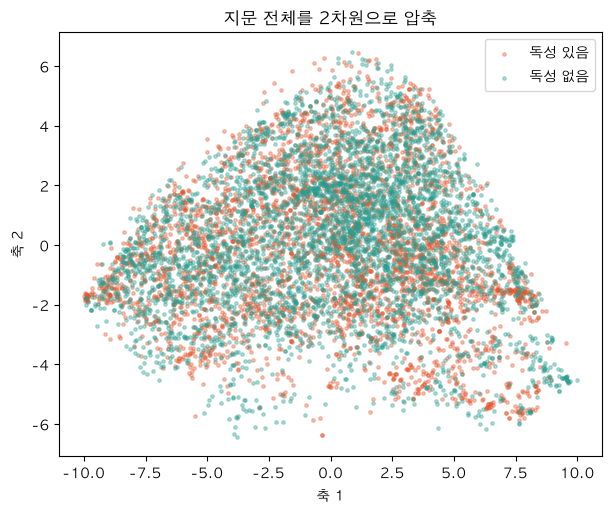

이 2개 축이 담은 정보 비율: 14.4%


In [15]:
from sklearn.decomposition import PCA
X = df[fp].values.astype(np.float32)
pca = PCA(n_components=2, random_state=0).fit(X)
Z = pca.transform(X)
plt.figure(figsize=(7,5.5))
plt.scatter(Z[df.label==0,0], Z[df.label==0,1], s=6, c=C0, alpha=.35, label='독성 있음')
plt.scatter(Z[df.label==1,0], Z[df.label==1,1], s=6, c=C1, alpha=.35, label='독성 없음')
plt.legend(); plt.xlabel('축 1'); plt.ylabel('축 2'); plt.title('지문 전체를 2차원으로 압축'); plt.show()
print('이 2개 축이 담은 정보 비율: %.1f%%' % (100*pca.explained_variance_ratio_.sum()))

→ 두 색이 완전히 겹쳐 있고 2개 축이 담은 정보도 적습니다. **단순한 그림이나 선 하나로는 못 가르고**, 모델이 많은 열을 함께 써야 한다는 뜻입니다.

## 8. 맛보기 모델: 어느 정도 맞출 수 있나?
랜덤포레스트(튜닝 전)를 5번 나눠 검증합니다. 과제의 주 평가지표는 **F1 점수**(1에 가까울수록 좋음)입니다.

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
cv = StratifiedKFold(5, shuffle=True, random_state=0)
res, preds = {}, {}
for name, cols in [('물성 4개만', num), ('지문+물성 전부', fp+num)]:
    p = cross_val_predict(RandomForestClassifier(200, n_jobs=-1, random_state=0), df[cols], df.label, cv=cv)
    res[name] = (accuracy_score(df.label,p), f1_score(df.label,p)); preds[name] = p
pd.DataFrame(res, index=['정확도','F1']).T.round(3)

,정확도,F1
물성 4개만,0.672,0.703
지문+물성 전부,0.800,0.819


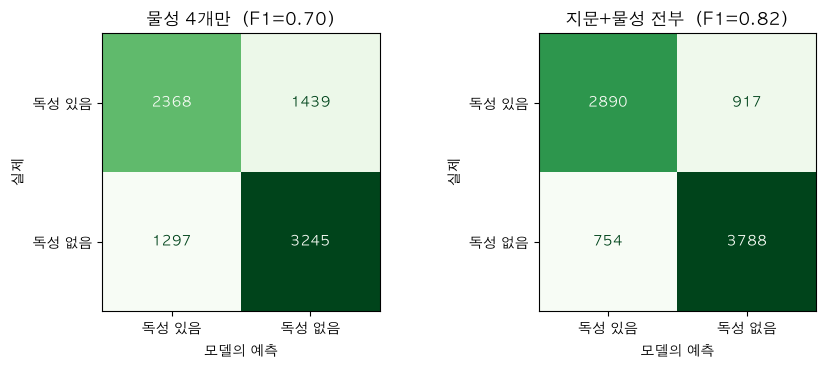

In [17]:
fig, ax = plt.subplots(1,2, figsize=(9,3.8))
for a,(n,p) in zip(ax, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(df.label,p), display_labels=['독성 있음','독성 없음']).plot(ax=a, colorbar=False, cmap='Greens')
    a.set_title(f'{n}  (F1={res[n][1]:.2f})'); a.set_xlabel('모델의 예측'); a.set_ylabel('실제')
plt.tight_layout(); plt.show()

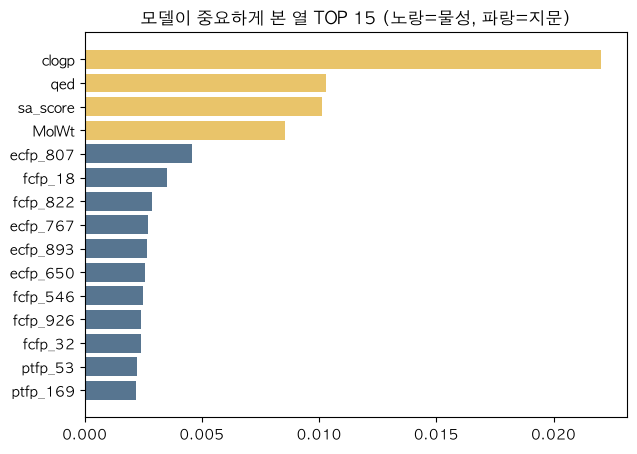

In [18]:
# 어떤 정보를 중요하게 썼나? (상위 15개)
rf = RandomForestClassifier(200, n_jobs=-1, random_state=0).fit(df[fp+num], df.label)
imp = pd.Series(rf.feature_importances_, index=fp+num).sort_values(ascending=False).head(15)[::-1]
plt.figure(figsize=(7,5)); plt.barh(imp.index, imp.values, color=['#e9c46a' if i in num else '#577590' for i in imp.index])
plt.title('모델이 중요하게 본 열 TOP 15 (노랑=물성, 파랑=지문)'); plt.show()

## 9. 정리
| 발견 | 의미 |
|---|---|
| 결측·중복 없음, 정답 54:46 | 데이터는 깨끗하고 균형적 |
| `clogp`만 독성과 뚜렷한 관계 | 기름에 잘 녹을수록 독성 위험↑ |
| 분자량 ↔ qed 상관 -0.75 | 중복 정보, 선형 모델 주의 |
| 지문 비트 하나하나는 약함 | 많이 모아 써야 효과 |
| 물성만 F1≈0.70 → 지문 포함 F1≈0.82 | 지문+물성 전부 사용 권장 |
| PTFP 49개 열은 항상 같은 값 | 모델링 전 제거 |

**다음 단계:** XGBoost/LightGBM 비교, 하이퍼파라미터 튜닝, F1 기준 임계값 조정